<h3/>
<h1 align="center">Universidad de Buenos Aires (FIUBA)</h1>
<h2 align="center">Especialización en Inteligencia Artificial - CEIA - FIUBA</h2>
<h2 align="center">Procesamiento del Lenguaje Natural I</h2>
<h3 align="center">Desafío 3 - Modelo de lenguaje con tokenización por caracteres</h3>

<p align="left">
Alumno:
  <ul>
    <li>Nicolás Lastra</li>
  </ul>
</p>

## Consigna

1. **Corpus.** Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
2. **Preprocesamiento.** Tokenizar el corpus por caracteres, estructurar el dataset y separar entre datos de entrenamiento y validación.
3. **Arquitecturas recurrentes.** Proponer arquitecturas basadas en unidades recurrentes (SimpleRNN, LSTM, GRU) para implementar el modelo de lenguaje, guiando el entrenamiento por la perplejidad en validación.
4. **Generación de secuencias.** Generar nuevas secuencias a partir de un contexto con greedy search y beam search determinístico y estocástico, observando en este último el efecto de la temperatura.

> **Cada experimento debe estar acompañado de una explicación o interpretación de lo observado**, incluido el sustento de las decisiones tomadas (por ejemplo, cambios de hiperparámetros). La notebook tiene que poder correrse de inicio a fin sin errores.

---
## 0. Librerías y datos

In [1]:
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import re
import os, sys, time
import json
from collections import Counter
from scipy.special import softmax
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import pad_sequences

# Definimos semilla para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Modelos entrenados y resultados
RUTA_MODELOS = "../docs/models/"
os.makedirs(RUTA_MODELOS, exist_ok=True)

I0000 00:00:1795458847.636140   51987 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795458847.673308   51987 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795458848.998755   51987 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# TensorFlow usa la GPU automáticamente si hay una disponible; si no, corre en CPU.
gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__} | Dispositivo: {'GPU (' + gpus[0].name + ')' if gpus else 'CPU'}")

TensorFlow 2.21.0 | Dispositivo: GPU (/physical_device:GPU:0)


---
## 1. Corpus: seleccion

Se reutiliza el corpus del desafio 2: **_Don Quijote de la Mancha_** (Miguel de Cervantes), en la versión de texto plano de [Project Gutenberg](https://www.gutenberg.org/ebooks/2000) versionada en `docs/data/`. Se lee desde GitHub fijando el commit, de modo que el archivo es siempre el mismo y la notebook corre igual en Colab que en una PC local. Usar el mismo libro permite además comparar lo que aprende un modelo por palabras (Word2Vec) con uno por caracteres.

In [3]:
# Corpus versionado en el repo (desafio 2), leído desde GitHub fijando el commit
# para que sea siempre el mismo archivo (funciona igual en Colab y en local).
URL = ("https://raw.githubusercontent.com/NicoLastra12/CEIA-Procesamiento_del_lenguaje_natural_I/"
       "6cb2818eadf2c7f176161dd485d2b11259628792/docs/data/quijote.txt")
texto = urllib.request.urlopen(URL).read().decode("utf-8")

# Se recorta encabezado y licencia de Gutenberg (igual que en el desafio 2)
inicio = texto.find("*** START OF")
fin = texto.find("*** END OF")
texto = texto[texto.find("\n", inicio) + 1 : fin].lower()
print(f"{len(texto):,} caracteres")

2,110,713 caracteres


---
## 2. Preprocesamiento: tokenización por caracteres y armado del dataset

In [4]:
#visualizamos la frecuencia de cada caracter, de menor a mayor
frec = Counter(texto)
frec.items()
for ch, n in sorted(frec.items(), key=lambda x: x[1]):
    print(repr(ch), n)

'à' 1
'7' 1
'5' 1
'2' 1
'3' 1
']' 2
'0' 2
'4' 2
'w' 2
'ù' 2
'6' 4
'ï' 4
'1' 8
'«' 57
'(' 62
')' 62
'ü' 89
'-' 109
'"' 166
'»' 290
'x' 380
'¡' 685
'!' 693
"'" 704
'¿' 959
'?' 960
'ú' 1279
':' 2047
'ñ' 4273
';' 4802
'z' 6543
'—' 6923
'á' 7173
'é' 7218
'f' 7624
'.' 8212
'ó' 9229
'j' 10616
'í' 12478
'g' 17348
'v' 17995
'h' 20011
'b' 24277
'y' 25213
'q' 32709
'p' 35601
'\n' 37679
',' 40277
'm' 44838
'c' 59916
't' 62248
'i' 78104
'u' 78779
'd' 87946
'l' 89699
'r' 101534
'n' 109218
's' 126537
'o' 154414
'a' 194623
'e' 223399
' ' 354684


In [5]:
# Observamos los lugar de aparicion de estos caracteres en el texto para entender el contexto.
for ch in ["à", "ù", "ï", "«", "]"]:
    for m in re.finditer(re.escape(ch), texto):
        print(repr(ch), "→", repr(texto[max(0, m.start()-30): m.end()+30]))

'à' → 'n quijote.\n\nforsi altro canterà con miglior plectio.\n\nfinis\n\n'
'ù' → 'ellano place; y adonde diga più, dice\nmás, y el su declara co'
'ù' → 'su declara con arriba, y el giù con abajo.\n\n— sí declaro, por'
'ï' → 'e, y ansimismo\ncon su rueda egïón no se detenga,\nni las herma'
'ï' → 'gra, y el famoso\ncampo de montïel, hasta el herboso\nllano de '
'ï' → ' junto a él,\nescudero el más fïel\nque vio el trato de escuder'
'ï' → '\nla más hermosa doncella\nque dïana vio en sus montes,\nque ven'
'«' → 'tan de mañana,\ndesta manera?: «apenas había el rubicundo apol'
'«' → ' de muy sabio y muy leído.\n\n— «principalmente, decían que sab'
'«' → 'siguió su cuento diciendo:\n\n— «asimesmo adevinaba cuándo habí'
'«' → 'ió pedro—, todo se sale allá. «y digo que con esto\nque decía '
'«' → 'e todo esto sabía, y aún\nmás. «finalmente, no pasaron muchos '
'«' → ' os replicaré más en\nnada.\n\n— «digo, pues, señor mío de mi al'
'«' → ', que es la que hace al caso. «y en lo demás\nsabréis q

In [6]:
# à y ù → a y u (palabras en italiano, 3 apariciones)
# ï se conserva (diéresis poética de los versos)
# « y », se conservan
# "]" se elimina (no aporta nada, no tiene su inicio "[", ademas baja frecuencia)

texto = texto.translate(str.maketrans({"à": "a", "ù": "u", "]": None}))

# Saltos de línea → espacio (son cortes de formato de Gutenberg, no del libro)
texto = re.sub(r"\s+", " ", texto).strip()

print(f"{len(texto):,} caracteres tiene el corpus | {len(set(texto))} caracteres distintos")

2,104,961 caracteres tiene el corpus | 58 caracteres distintos


In [7]:
# chars_vocab: conjunto de caracteres únicos del corpus.
# Se ordena para que los índices sean siempre los mismos entre corridas (un set no garantiza el orden).
chars_vocab = sorted(set(texto))
vocab_size = len(chars_vocab)

# diccionarios caracter <-> índice. char2idx funciona como tokenizador.
char2idx = {ch: i for i, ch in enumerate(chars_vocab)}
idx2char = {i: ch for ch, i in char2idx.items()}

print(f"Tamaño del vocabulario: {vocab_size} caracteres") # tamaño del vocabulario
print(f"Caracteres en el corpus: {len(texto):,}")         # tamaño del corpus

Tamaño del vocabulario: 58 caracteres
Caracteres en el corpus: 2,104,961


In [8]:
# Tamaño de la ventana de contexto (en caracteres)
MAX_CONTEXT_SIZE = 100

# Tokenizamos el texto completo
tokenized_text = [char2idx[ch] for ch in texto]

In [9]:
# separaremos el dataset entre entrenamiento y validación.
# "p_val" será la proporción del corpus que se reservará para validación
# "num_val" es la cantidad de secuencias de tamaño "max_context_size" que se usará en validación

p_val = 0.1
num_val = int(np.ceil(len(tokenized_text)*p_val/MAX_CONTEXT_SIZE))

#Realizamos la separacion del texto en train y validation
train_text = tokenized_text[:-num_val*MAX_CONTEXT_SIZE]
validation_text = tokenized_text[-num_val*MAX_CONTEXT_SIZE:]


In [10]:
# STRIDE : Define cada cuantos caracteres empieza una ventana nueva
STRIDE = 3

# Se estructura el problema como many-to-many:
#   X = [x_0, ..., x_N]  ->  y = [x_1, ..., x_N+1]

train_array = np.array(train_text, dtype=np.uint8)   # 58 caracteres < 256 → uint8 alcanza
ventanas = np.lib.stride_tricks.sliding_window_view(train_array, MAX_CONTEXT_SIZE + 1)[::STRIDE]
X = np.ascontiguousarray(ventanas[:, :-1])  # cada ventana menos la ultima columna
y = np.ascontiguousarray(ventanas[:, 1:])   # cada ventana menos la primer columna

# Validación: bloques consecutivos de MAX_CONTEXT_SIZE sin solapar,
# separados en entrada (caracteres 0..98) y target (caracteres 1..99)
val_seqs = np.array(validation_text, dtype=np.uint8).reshape(num_val, MAX_CONTEXT_SIZE)
X_val = val_seqs[:, :-1]
y_val = val_seqs[:, 1:]

print(f"X: {X.shape}, y: {y.shape}, X_val: {X_val.shape}, y_val: {y_val.shape}")

X: (631454, 100), y: (631454, 100), X_val: (2105, 99), y_val: (2105, 99)


**Análisis:**

El texto se pasó a minúsculas y se revisaron los caracteres poco frecuentes viendo su contexto:

| Caracter | Apariciones | Qué es | Decisión |
|---|---|---|---|
| `à`, `ù` | 3 | Palabras en italiano (*canterà*, *più*, *giù*) | Se reemplazan por `a` y `u` |
| `ï` | 4 | Dieresis poetica de los versos (*fïel*, *dïana*) | Se conserva |
| `]` | 2 | Resto de la edición (sin su `[` de apertura) | Se elimina |
| `«` / `»` | 57 / 290 | Comillas de cita; `»` también abre cada párrafo de una cita larga (comillas de seguimiento) | Se conservan |
| `\n` | 37.679 | En su mayoría cortes de línea de Gutenberg, no del libro | Se reemplazan por espacio |

Se conservan la puntuación y los signos de diálogo (`—`, `¿?`, `¡!`) porque el objetivo es generar texto con la forma del libro. A nivel caracter, cada signo suma un solo token al vocabulario. El corpus queda en 2.104.961 caracteres y el vocabulario baja de 62 a **58** caracteres. El vocabulario se ordena (`sorted`) para que los índices sean siempre los mismos entre corridas.

**Dataset.** Se usa una ventana de contexto de 100 caracteres y se plantea el problema como *many-to-many*: el target es la entrada corrida una posición, así que cada ventana aporta 100 predicciones. Para validar se reserva el **10% final** del libro como un bloque continuo, para que el modelo se evalúe sobre texto que no vio (con ventanas solapadas, separar al azar mezclaría train y validación). Las ventanas de entrenamiento se arman con `sliding_window_view` en `uint8` y `STRIDE = 3`, lo que da 631.454 ventanas. Con stride 3, cada caracter sigue apareciendo en aproximadamente 33 ventanas, y la memoria baja de 5 GB (listas de la cátedra) a aproximadamente 130 MB. La validación queda en 2.105 bloques de 100 caracteres (99 predicciones cada uno).

---
## 3. Arquitecturas recurrentes

In [11]:
# Callback: calcula la perplejidad en validación al final de cada época, guarda el mejor modelo
# y corta el entrenamiento (early stopping) si no mejora en "patience" épocas.
#
# A diferencia de la clase tomada de la catedra, esta no arma los prefijos con padding, como el modelo es
# many-to-many y la RNN es causal, la salida en la posición t ya es la predicción del caracter t+1 dado el
# prefijo [0..t]. Es la misma cuenta con ~100 veces menos predicciones.

class PplCallback(keras.callbacks.Callback):
    def __init__(self, X_val, y_val, ruta_modelo, patience=5, batch_size=512):
        super().__init__()
        self.X_val = X_val
        self.y_val = y_val.astype(np.int64)
        self.ruta_modelo = ruta_modelo
        self.patience = patience
        self.batch_size = batch_size
        self.history_ppl = []
        self.min_score = np.inf
        self.patience_counter = 0

    def on_epoch_end(self, epoch, logs=None):
        probs = self.model.predict(self.X_val, batch_size=self.batch_size, verbose=0)

        # Probabilidad que el modelo le dio al caracter que realmente venía
        p_target = np.take_along_axis(probs, self.y_val[..., None], axis=-1)[..., 0]

        # Perplejidad de cada secuencia (vía logaritmos) y promedio entre secuencias
        ppl_por_secuencia = np.exp(-np.mean(np.log(p_target + 1e-10), axis=1))
        score = float(np.mean(ppl_por_secuencia))
        self.history_ppl.append(score)

        if score < self.min_score:
            self.min_score = score
            self.patience_counter = 0
            self.model.save(self.ruta_modelo)
            msg = "mejor modelo guardado"
        else:
            self.patience_counter += 1
            msg = f"sin mejora ({self.patience_counter}/{self.patience})"
            if self.patience_counter >= self.patience:
                self.model.stop_training = True
                msg += " → se detiene"
        print(f"  perplejidad val: {score:.3f} | {msg}")

In [12]:
# Las tres arquitecturas son iguales salvo la celda recurrente, para compararlas en igualdad de condiciones.
CELDAS = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

def construir_modelo(tipo_celda, unidades=200, dim_embedding=32, dropout=0.2):
    keras.utils.set_random_seed(SEED)    # misma inicialización para cada modelo
    modelo = keras.Sequential([
        keras.Input(shape=(None,)),                             # secuencias de cualquier largo
        layers.Embedding(vocab_size, dim_embedding),            # índice → vector denso por caracter
        CELDAS[tipo_celda](unidades, return_sequences=True),    # una salida por paso (many-to-many)
        layers.Dropout(dropout),                                # regularización fuera de la celda (permite cuDNN)
        layers.Dense(vocab_size, activation="softmax"),         # distribución del próximo caracter
    ], name=tipo_celda)
    modelo.compile(loss="sparse_categorical_crossentropy", optimizer="rmsprop")
    return modelo


def entrenar(tipo_celda, epochs=30, batch_size=512, patience=5, **kwargs):
    modelo = construir_modelo(tipo_celda, **kwargs)
    modelo.summary()
    ppl_cb = PplCallback(X_val, y_val, RUTA_MODELOS + f"{tipo_celda}.keras", patience=patience)

    inicio = time.time()
    hist = modelo.fit(X, y, epochs=epochs, batch_size=batch_size, callbacks=[ppl_cb], verbose=2)
    duracion = time.time() - inicio

    return {
        "celda": tipo_celda,
        "parametros": modelo.count_params(),
        "epocas": len(ppl_cb.history_ppl),
        "mejor_ppl_val": ppl_cb.min_score,
        "seg_por_epoca": duracion / len(ppl_cb.history_ppl),
        "ppl_val": ppl_cb.history_ppl,
        "loss_train": hist.history["loss"],
    }

# Acá se van guardando los resultados de cada modelo para la comparación final
resultados = {}

In [13]:
# True: entrena los tres modelos (~1 h con GPU local, ~1,5 h en Colab).
# False: carga los modelos y resultados guardados en docs/models/.
ENTRENAR = True

In [14]:
# Modelos y resultados versionados en el repo, fijados a un commit para que sean siempre los mismos.
# Si no están en RUTA_MODELOS (por ejemplo, al correr en Colab), se descargan desde GitHub.

URL_MODELOS = ("https://raw.githubusercontent.com/NicoLastra12/CEIA-Procesamiento_del_lenguaje_natural_I/"
               "HASH_DEL_COMMIT/docs/models/")
ARCHIVOS_MODELOS = ["SimpleRNN.keras", "LSTM.keras", "GRU.keras", "resultados.json"]

if not ENTRENAR:
    for archivo in ARCHIVOS_MODELOS:
        destino = RUTA_MODELOS + archivo
        if not os.path.exists(destino):
            urllib.request.urlretrieve(URL_MODELOS + archivo, destino)
            print(f"Descargado: {archivo}")

### 3.1 SimpleRNN (celda de Elman)

In [15]:
if ENTRENAR:
    resultados["SimpleRNN"] = entrenar("SimpleRNN")

I0000 00:00:1795458851.894177   51987 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 32)       │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, None, 200)      │        46,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, None, 200)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 58)       │        11,658 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,114 (234.82 KB)

 Trainable params: 60,114 (234.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


I0000 00:00:1795458853.548793   52158 service.cc:153] XLA service 0x45c56f10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795458853.548820   52158 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795458853.586577   52158 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
W0000 00:00:1795458853.616788   52158 assert_op.cc:39] Ignoring Assert operator compile_loss/sparse_categorical_crossentropy/SparseSoftmaxCrossEntropyWithLogits/assert_equal_1/Assert/Assert
I0000 00:00:1795458853.678966   52158 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795458853.723806   52158 dot_merger.cc:481] Merging Dots in computation: SimpleRNN_1_simple_rnn_1_while_body_1155_grad_1409_const_0__.22.clone.clone.clone.clone.clone.clone.clone
I0000 00:00:179545885

  perplejidad val: 5.347 | mejor modelo guardado
1234/1234 - 74s - 60ms/step - loss: 1.9291
Epoch 2/30
  perplejidad val: 4.745 | mejor modelo guardado
1234/1234 - 60s - 49ms/step - loss: 1.6392
Epoch 3/30
  perplejidad val: 4.541 | mejor modelo guardado
1234/1234 - 80s - 65ms/step - loss: 1.5651
Epoch 4/30
  perplejidad val: 4.467 | mejor modelo guardado
1234/1234 - 59s - 48ms/step - loss: 1.5301
Epoch 5/30
  perplejidad val: 4.382 | mejor modelo guardado
1234/1234 - 59s - 47ms/step - loss: 1.5095
Epoch 6/30
  perplejidad val: 4.329 | mejor modelo guardado
1234/1234 - 56s - 45ms/step - loss: 1.4957
Epoch 7/30
  perplejidad val: 4.311 | mejor modelo guardado
1234/1234 - 57s - 46ms/step - loss: 1.4858
Epoch 8/30
  perplejidad val: 4.288 | mejor modelo guardado
1234/1234 - 56s - 46ms/step - loss: 1.4785
Epoch 9/30
  perplejidad val: 4.279 | mejor modelo guardado
1234/1234 - 54s - 44ms/step - loss: 1.4728
Epoch 10/30
  perplejidad val: 4.261 | mejor modelo guardado
1234/1234 - 55s - 44ms/

### 3.2 LSTM

In [16]:
if ENTRENAR:
  resultados["LSTM"] = entrenar("LSTM")

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, None, 32)       │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 200)      │       186,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, None, 200)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, None, 58)       │        11,658 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 199,914 (780.91 KB)

 Trainable params: 199,914 (780.91 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
  perplejidad val: 6.004 | mejor modelo guardado
1234/1234 - 27s - 22ms/step - loss: 2.1020
Epoch 2/30
  perplejidad val: 5.021 | mejor modelo guardado
1234/1234 - 25s - 21ms/step - loss: 1.7172
Epoch 3/30
  perplejidad val: 4.643 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.5980
Epoch 4/30
  perplejidad val: 4.426 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.5329
Epoch 5/30
  perplejidad val: 4.282 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.4899
Epoch 6/30
  perplejidad val: 4.178 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.4589
Epoch 7/30
  perplejidad val: 4.108 | mejor modelo guardado
1234/1234 - 24s - 20ms/step - loss: 1.4354
Epoch 8/30
  perplejidad val: 4.047 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.4165
Epoch 9/30
  perplejidad val: 4.002 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.4010
Epoch 10/30
  perplejidad val: 3.967 | mejor modelo guardado
1234/1234 - 

### 3.3 GRU

In [17]:
if ENTRENAR:
  resultados["GRU"] = entrenar("GRU")

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, None, 32)       │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 200)      │       140,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, None, 200)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, None, 58)       │        11,658 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153,914 (601.23 KB)

 Trainable params: 153,914 (601.23 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
  perplejidad val: 5.133 | mejor modelo guardado
1234/1234 - 27s - 22ms/step - loss: 1.9613
Epoch 2/30
  perplejidad val: 4.327 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.5580
Epoch 3/30
  perplejidad val: 4.068 | mejor modelo guardado
1234/1234 - 25s - 20ms/step - loss: 1.4434
Epoch 4/30
  perplejidad val: 3.943 | mejor modelo guardado
1234/1234 - 26s - 21ms/step - loss: 1.3899
Epoch 5/30
  perplejidad val: 3.879 | mejor modelo guardado
1234/1234 - 27s - 22ms/step - loss: 1.3577
Epoch 6/30
  perplejidad val: 3.834 | mejor modelo guardado
1234/1234 - 26s - 21ms/step - loss: 1.3357
Epoch 7/30
  perplejidad val: 3.800 | mejor modelo guardado
1234/1234 - 26s - 21ms/step - loss: 1.3195
Epoch 8/30
  perplejidad val: 3.786 | mejor modelo guardado
1234/1234 - 26s - 21ms/step - loss: 1.3071
Epoch 9/30
  perplejidad val: 3.775 | mejor modelo guardado
1234/1234 - 26s - 21ms/step - loss: 1.2972
Epoch 10/30
  perplejidad val: 3.770 | mejor modelo guardado
1234/1234 - 

In [18]:
# Si se entrenó en esta sesión se guardan los resultados, si no, se cargan los guardados
ruta_resultados = RUTA_MODELOS + "resultados.json"

if ENTRENAR:
    with open(ruta_resultados, "w") as f:
        json.dump(resultados, f)
else:
    with open(ruta_resultados) as f:
        resultados = json.load(f)

,parametros,epocas,mejor_ppl_val,seg_por_epoca
celda,,,,
SimpleRNN,60114,30,4.205,58.450
LSTM,199914,30,3.708,25.395
GRU,153914,19,3.748,25.881


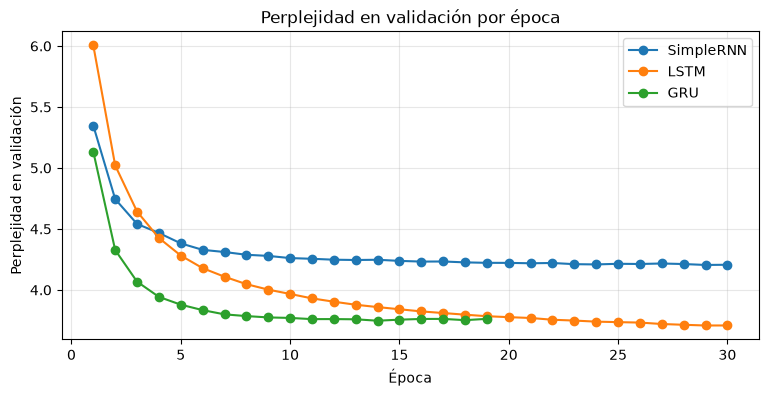

In [19]:
# Tabla comparativa de los tres modelos
tabla = pd.DataFrame(resultados.values()).set_index("celda")
display(tabla[["parametros", "epocas", "mejor_ppl_val", "seg_por_epoca"]].round(3))

# Curvas de perplejidad en validación superpuestas
fig, ax = plt.subplots(figsize=(9, 4))
for r in resultados.values():
    ax.plot(range(1, r["epocas"] + 1), r["ppl_val"], marker="o", label=r["celda"])
ax.set_xlabel("Época")
ax.set_ylabel("Perplejidad en validación")
ax.set_title("Perplejidad en validación por época")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Análisis:**

Las tres arquitecturas son iguales salvo en su celda recurrente (SimpleRNN, LSTM o GRU): `Embedding` de 32 dimensiones, una capa recurrente de 200 unidades con `return_sequences=True`, `Dropout(0.2)` y `Dense` con softmax sobre los 58 caracteres, con `rmsprop` como optimizador, batch de 512, hasta 30 épocas y early stopping con paciencia 5 sobre la perplejidad de validación. Se usa `Embedding` en vez del one-hot de la cátedra porque aprende un vector denso por caracter. El dropout va fuera de la celda (sin `recurrent_dropout`) para que LSTM y GRU usen cuDNN en GPU. El callback calcula la perplejidad sin armar prefijos con padding, como la red es causal, la salida en cada posición ya es la predicción del caracter siguiente, y el cálculo es el mismo con casi 100 veces menos predicciones.

| Modelo | Parámetros | Épocas | Mejor perplejidad (val) | s/época |
|---|---|---|---|---|
| SimpleRNN | 60.114 | 30 | 4,205 | 58,5 |
| LSTM | 199.914 | 30 | **3,708** | 25,4 |
| GRU | 153.914 | 19 (mejor en la 14) | 3,748 | 25,9 |

- **LSTM** es la mejor y seguía mejorando lentamente al llegar a las 30 épocas, así que con más épocas probablemente bajaría un poco más.
- **GRU** converge mucho más rápido (3,94 en la época 4, contra 4,43 de la LSTM), pero se estanca alrededor de 3,75 desde la época 10 y corta en la 19. Su loss de entrenamiento siguió bajando mientras la perplejidad de validación quedaba en 3,75, empezando a sobreajustar.
- **SimpleRNN** queda claramente peor y se aplana alrededor de 4,2. Su perplejidad de entrenamiento es prácticamente igual a la de validación, así que no sobreajusta, está limitada por su capacidad de recordar contexto (el gradiente se desvanece después de pocos pasos).
- **Tiempo:** la SimpleRNN tarda más del doble por época que la LSTM y la GRU (58,5 s contra 25,6 s), aunque tiene 3 veces menos parámetros que la LSTM. LSTM y GRU usan la implementación de cuDNN, que procesa la secuencia completa en la GPU, mientras que la SimpleRNN no tiene versión cuDNN y Keras la recorre paso a paso.

---
## 4. Generación de secuencias

In [20]:
# Se cargan los mejores modelos guardados por el callback durante el entrenamiento (sección 3).
# El archivo .keras guarda la arquitectura y los pesos, así que no hace falta reentrenar ni
# volver a construir el modelo. Funciona igual en CPU aunque se hayan entrenado en GPU.
modelos = {celda: keras.models.load_model(RUTA_MODELOS + f"{celda}.keras") for celda in CELDAS}

# Para la generación se usa el de menor perplejidad en validación (ver tabla de la sección 3)
mejor = min(resultados.values(), key=lambda r: r["mejor_ppl_val"])["celda"]
modelo = modelos[mejor]
print(f"Modelo usado para la generación: {mejor}")

Modelo usado para la generación: LSTM


In [21]:
# Texto → lista de índices. Sin padding, el modelo acepta secuencias de cualquier largo,
# y el índice 0 es el espacio, así que rellenar con ceros equivaldría a anteponer espacios.
def encode(texto):
    texto = texto.lower()
    faltantes = set(texto) - set(char2idx)
    if faltantes:
        raise ValueError(f"Caracteres fuera del vocabulario: {faltantes}")
    return [char2idx[ch] for ch in texto]

# Lista de índices → texto
def decode(ids):
    return "".join(idx2char[i] for i in ids)

# Distribución del próximo caracter para una o varias secuencias (todas del mismo largo).
# Se usan los últimos MAX_CONTEXT_SIZE caracteres, la misma ventana que en el entrenamiento.
# Se llama al modelo directo en vez de model.predict, que tiene mucho costo fijo por llamada.
def probs_siguiente(modelo, secuencias):
    x = np.array([s[-MAX_CONTEXT_SIZE:] for s in secuencias])
    return modelo(x, training=False)[:, -1, :].numpy()

### 4.1 Greedy search

In [22]:
# Greedy: en cada paso se elige el caracter más probable (argmax) y se agrega a la secuencia.
def generar_greedy(modelo, semilla, n_chars=200):
    ids = encode(semilla)
    for _ in range(n_chars):
        probs = probs_siguiente(modelo, [ids])[0]
        ids.append(int(np.argmax(probs)))
    return decode(ids)

SEMILLAS = ["en un lugar de la mancha", "dijo sancho", "don quijote"]
for semilla in SEMILLAS:
    print(repr(generar_greedy(modelo, semilla, 200)), "\n")


'en un lugar de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la man' 

'dijo sancho—, que esto se le dijo: — señor —respondió sancho—, que es el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha' 

'don quijote de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caball' 



In [23]:
# Misma semilla con los tres modelos, para comparar la calidad del texto generado
for celda, m in modelos.items():
    print(f"{celda}:\n{generar_greedy(m, 'dijo sancho', 200)!r}\n")

SimpleRNN:
'dijo sancho—, que estaba en la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la mano a la '

LSTM:
'dijo sancho—, que esto se le dijo: — señor —respondió sancho—, que es el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha, y el caballero de la mancha'

GRU:
'dijo sancho—, que es el caballero de la mancha, que está en el mundo que está en el mundo que está en el mundo que está en el mundo de la mano a la mano a la mano de la mano de la mano de la mano de la mano de l'



### 4.2 Beam search determinístico

In [24]:
rng = np.random.default_rng(SEED)

# Beam search: mantiene las "num_beams" secuencias candidatas con mayor probabilidad acumulada.
# En cada paso, cada candidata se extiende con los vocab_size caracteres posibles y se eligen
# num_beams entre todas esas extensiones:

#   - modo="det": las num_beams de mayor log-probabilidad (determinístico)
#   - modo="sto": se muestrean num_beams según softmax(log-prob / temp) (estocástico)


# La log-probabilidad acumulada es la suma de los log de cada paso (regla de la cadena)
def beam_search(modelo, semilla, n_chars=200, num_beams=5, modo="det", temp=1.0):
    beams = [encode(semilla)]          # secuencias candidatas
    scores = np.zeros(1)               # log-probabilidad acumulada de cada una
    for _ in range(n_chars):
        probs = probs_siguiente(modelo, beams)
        candidatos = (scores[:, None] + np.log(probs + 1e-10)).ravel()
        if modo == "det":
            elegidos = np.argsort(candidatos)[::-1][:num_beams]
        elif modo == "sto":
            p = softmax(candidatos / temp) + 1e-12        # evita probabilidades exactamente 0
            elegidos = rng.choice(candidatos.size, size=num_beams, replace=False, p=p / p.sum())
        else:
            raise ValueError(f"modo debe ser 'det' o 'sto', se recibió {modo!r}")

        beam_origen, caracter = np.divmod(elegidos, probs.shape[1])
        beams = [beams[b] + [int(c)] for b, c in zip(beam_origen, caracter)]
        scores = candidatos[elegidos]
    orden = np.argsort(scores)[::-1]
    return [(decode(beams[i]), float(scores[i])) for i in orden]

In [25]:
# Las 5 secuencias finales, ordenadas por log-probabilidad acumulada (más alta = más probable)
for texto, score in beam_search(modelo, "dijo sancho", 200, num_beams=5, modo="det"):
    print(f"{score:8.2f}  {texto!r}\n")

 -112.93  'dijo sancho—, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, porque no había de hacer la caballeriza de la mancha, porque el caballero andante que le había de ser'

 -113.49  'dijo sancho—, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, porqu'

 -114.19  'dijo sancho—, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, que e'

 -114.22  'dijo sancho—, porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha, porque no había de hacer la caballeriza de la mancha, porque el caballero andante que le había de hac'

 -114.31  'dijo sancho—, porque no había de hacer la caballeriza de la mancha, porque el caballero a

### 4.3 Beam search estocástico y efecto de la temperatura

In [26]:
# Misma semilla con distintas temperaturas, se muestra la mejor secuencia de cada corrida
pd.set_option("display.max_colwidth", None)
filas = []
for temp in [0.25, 0.5, 1.0, 1.5, 2.0]:
    texto, score = beam_search(modelo, "dijo sancho", 200, num_beams=5, modo="sto", temp=temp)[0]
    filas.append({"temperatura": temp, "log_prob": round(score, 2), "texto": texto})
display(pd.DataFrame(filas))

,temperatura,log_prob,texto
0,0.25,-116.44,"dijo sancho—, porque no se había de ser de los caballeros andantes, que no se le había de ser de lo que había de hacer que no se ha de ser en el caballero de la mancha, que está en el caballero de la mancha, que"
1,0.50,-125.28,"dijo sancho—, que, aunque no se ha de ser lo que se le había de ser alguna cosa de la mancha, porque el señor don quijote de la mancha, como lo que no se había de ser de lo que había de ser alguno de las manos,"
2,1.00,-129.88,"dijo sancho— que esto dicho, señor don quijote, y más, que no tenía de parecerles que sancho panza, porque el suelo que estaba vuestra merced, señor don quijote, que está en esta verdad, que no se había de ser e"
3,1.50,-171.49,"dijo sancho—, que le había de quedar a los ojos le había de parte de la tierra. porque yo quiere dicha acabada de su suerte de los entretenilles y satisfacientes, en su señor la nuestra valiencia, y está en el m"
4,2.00,-198.51,"dijo sancho—, que no llega volviendo el caballero del padres a mí que aquél por de atrevido camila habéis de poder caballero, de partimonio, dijo: — a quien te puede ser con ella sancho de la margula con todo aq"


**Análisis:**

**Greedy.** El modelo aprendió a escribir palabras correctas, espacios y puntuación, e incluso a armar diálogos con raya (`dijo sancho—, que esto se le dijo: — señor —respondió sancho—, ...`). Pero greedy cae siempre en un bucle: al elegir el caracter más probable, una vez que genera una frase frecuente el contexto se repite y vuelve a elegir lo mismo. Con la LSTM, las tres semillas terminan en `", y el caballero de la mancha"`. Con la misma semilla, la SimpleRNN cae enseguida en un ciclo corto (`"a la mano a la mano..."`), coherente con su menor memoria, y la GRU pasa por un ciclo (`"que está en el mundo"`) antes de terminar en uno parecido.

**Beam search determinístico.** Con 5 candidatas también genera un ciclo (`"porque no había de hacer la caballeriza de la mancha, porque el caballero andante de la mancha"`), más largo que el de greedy, y las 5 secuencias son casi idénticas, solo difieren en los últimos caracteres. Buscar la secuencia más probable favorece las frases más comunes del corpus, por eso no resuelve la repetición. 

**Beam search estocástico y temperatura.** El azar rompe los bucles. Como todas las secuencias generadas miden 200 caracteres, la log-probabilidad se puede pasar a perplejidad por caracter:

| Temperatura | log-prob | Perplejidad por caracter | Texto |
|---|---|---|---|
| 0,25 | −116,4 | 1,79 | Frases frecuentes que se repiten ("había de ser"), parecido a greedy |
| 0,5 | −125,3 | 1,87 | Gramatical, con expresiones del libro ("el señor don quijote de la mancha"), algo repetitivo |
| 1,0 | −129,9 | 1,91 | Variado y con el estilo del libro ("vuestra merced", "señor don quijote", "sancho panza") |
| 1,5 | −171,5 | 2,36 | La sintaxis se rompe y aparecen palabras raras o inventadas ("satisfacientes", "valiencia") |
| 2,0 | −198,5 | 2,70 | Inventa palabras ("partimonio", "margula") y frases sin sentido |

La temperatura regula el compromiso entre coherencia y diversidad, valores bajos concentran la probabilidad en las candidatas más probables y valores altos la reparten. El mejor equilibrio está entre **T = 0,5 y T = 1,0**. En todas las temperaturas el texto arranca con la raya de diálogo después de `dijo sancho`, es tan probable después de esa semilla que ni con T = 2 se elige otra cosa.


---

## Conclusiones

- Un modelo de lenguaje por caracteres entrenado con un solo libro (~2,1 millones de caracteres) aprende ortografía, puntuación, diálogos y frases típicas del Quijote, con un vocabulario de solo 58 caracteres.
- El preprocesamiento depende de la tarea, a diferencia del desafio 2 (Word2Vec), acá se conservan la puntuación y los signos de diálogo porque forman parte del texto a generar, y solo se limpian los cortes de línea del formato y caracteres aislados.
- Las celdas con compuertas superan claramente a la SimpleRNN (3,71 y 3,75 contra 4,21 de perplejidad). La LSTM logra la mejor perplejidad y seguía mejorando a las 30 épocas, la GRU converge más rápido con menos parámetros, pero empieza a sobreajustar antes. Gracias a cuDNN, ambas entrenan más del doble de rápido que la SimpleRNN.
- Una métrica baja no alcanza para generar buen texto, greedy y beam search determinístico caen en bucles de frases frecuentes. El muestreo con temperatura los evita, y una temperatura entre 0,5 y 1,0 da el mejor equilibrio entre coherencia y variedad.
- Posibles mejoras: entrenar la LSTM más épocas, sumar una segunda capa recurrente o más unidades, y usar regularización más fuerte en la GRU.